In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [11]:
df_2d = pd.read_csv('data/data_2d.csv')
df_2d.head()

,0.000000000000000000e+00,-7.687164597386728637e-01,4.608603078297135447e-01
0,0.0,2.687848,2.366961
1,0.0,-0.201379,0.470430
2,0.0,0.608496,1.225400
3,0.0,-0.082282,1.137218
4,0.0,2.083069,2.694482


In [12]:
wcss = []

In [13]:
for i in range(1, 11):
  kmeans = KMeans(n_clusters=i, random_state=42, n_init='auto')
  kmeans.fit(df_2d)
  wcss.append(kmeans.inertia_)


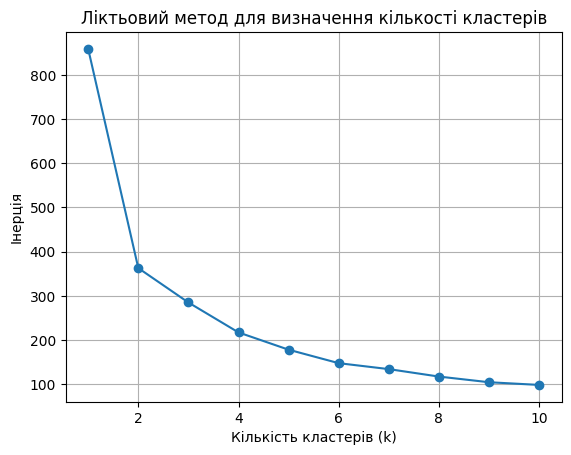

In [14]:
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Ліктьовий метод для визначення кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція')
plt.grid(True)
plt.show()

In [15]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init='auto')

In [18]:
X_2d = df_2d.iloc[:, 1:]

In [19]:
labels = kmeans_final.fit_predict(X_2d)

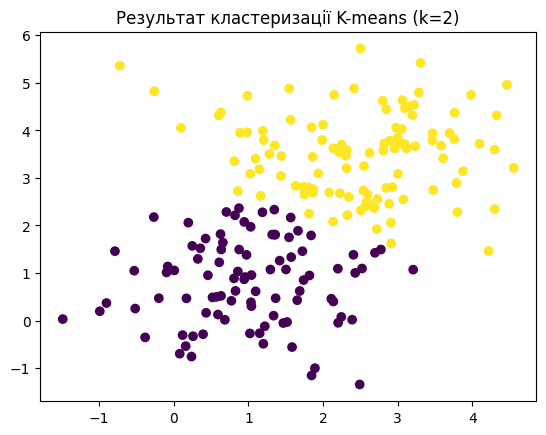

In [21]:
plt.scatter(X_2d.iloc[:, 0], X_2d.iloc[:, 1], c=labels, cmap='viridis')
plt.title('Результат кластеризації K-means (k=2)')
plt.show()

In [22]:
df_mnist = pd.read_csv('data/mnist.csv')

In [24]:
pca = PCA(n_components=2)
mnist_2d = pca.fit_transform(df_mnist)

In [25]:
wcss_mnist = []

In [26]:
for i in range(1, 16):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init='auto')
    kmeans.fit(mnist_2d)
    wcss_mnist.append(kmeans.inertia_)

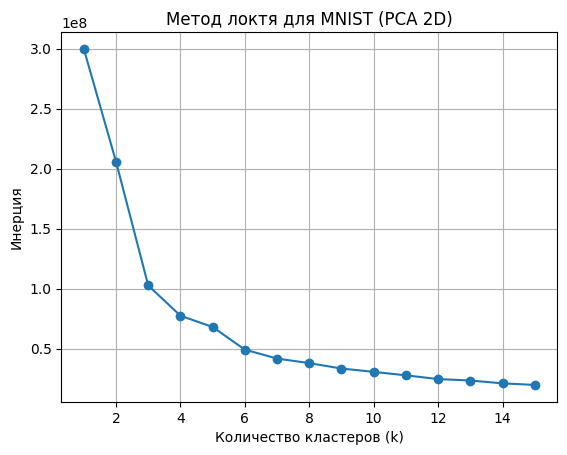

In [27]:
plt.plot(range(1, 16), wcss_mnist, marker='o')
plt.title('Ліктьовий метод для визначення кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Інерція')
plt.grid(True)
plt.show()

In [28]:
kmeans_mnist = KMeans(n_clusters=10, random_state=42, n_init='auto')

In [29]:
labels_mnist = kmeans_mnist.fit_predict(mnist_2d)

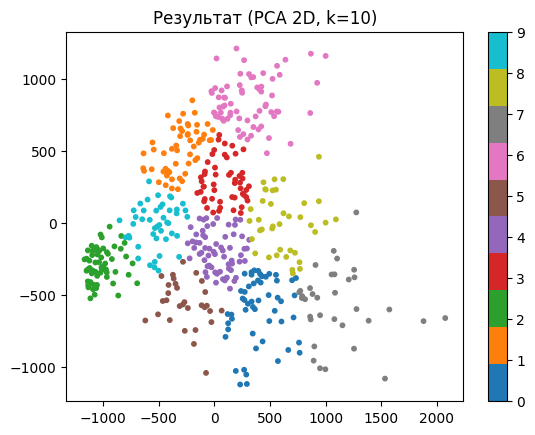

In [33]:
plt.scatter(mnist_2d[:, 0], mnist_2d[:, 1], c=labels_mnist, cmap='tab10', s=10)
plt.title('Результат (PCA 2D, k=10)')
plt.colorbar()
plt.show()